<python>\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


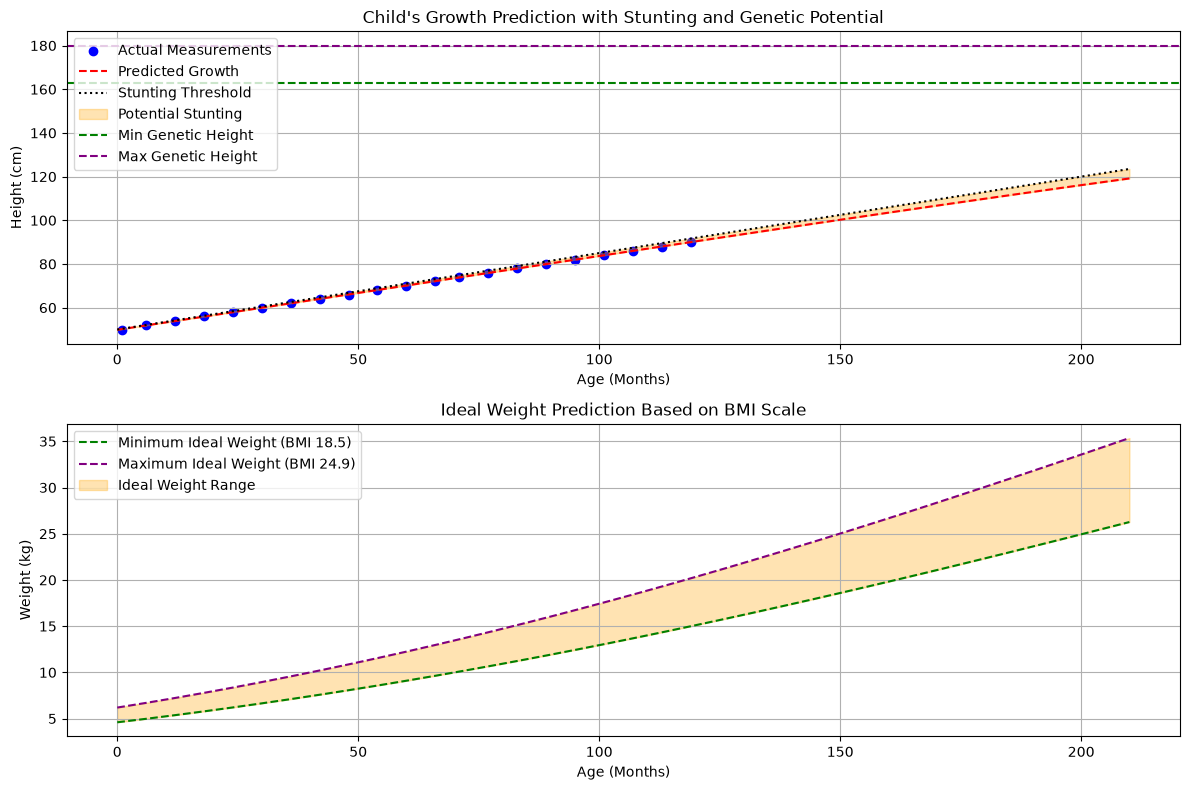

In [1]:
from pathlib import Path
DATA = Path.cwd().parent / "data"

# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Load Data
biodata_pasien_path = DATA / "biodata_pasien.xlsx"
pengkajian_pasien_path = DATA / "pengkajian_pasien.xlsx"

# Read the data from Excel files
biodata_df = pd.read_excel(biodata_pasien_path)
pengkajian_df = pd.read_excel(pengkajian_pasien_path)

# Get the patient's details (John Doe in this case)
patient = biodata_df[biodata_df['pasien_id'] == '8ddfe7ed-f7e8-4d4b-a31f-97a298d5d82e'].iloc[0]

# Extract patient details
gender = patient['kelamin'].lower()  # 'male' or 'female'
father_height = pengkajian_df['tinggi_bapak'].iloc[0]
mother_height = pengkajian_df['tinggi_ibu'].iloc[0]

# Predict height range using genetic formula
def predict_genetic_height(gender, father_height, mother_height):
    if gender == 'laki-laki':
        return ((mother_height + 13) + father_height) / 2, 8.5
    elif gender == 'perempuan':
        return ((father_height - 13) + mother_height) / 2, 8.5
    else:
        raise ValueError("Gender must be 'laki-laki' or 'perempuan'")

# Ideal weight prediction using BMI
def predict_ideal_weight(height_cm):
    # Convert cm to meters
    height_m = height_cm / 100
    # Ideal BMI range
    bmi_range = [18.5, 24.9]
    # Calculate ideal weight
    min_ideal_weight = bmi_range[0] * (height_m ** 2)
    max_ideal_weight = bmi_range[1] * (height_m ** 2)
    return min_ideal_weight, max_ideal_weight

# Predict genetic height
expected_height, margin = predict_genetic_height(gender, father_height, mother_height)
min_expected_height = expected_height - margin
max_expected_height = expected_height + margin

# Extract growth data from 'pengkajian_pasien' for height and weight over time
pengkajian_df['tanggal'] = pd.to_datetime(pengkajian_df['tanggal'])
pengkajian_df['months'] = pengkajian_df['tanggal'].dt.month + (pengkajian_df['tanggal'].dt.year - pengkajian_df['tanggal'].dt.year.min()) * 12

# Use actual data for growth predictions
df_growth = pengkajian_df[['months', 'tinggi']].dropna()
df_growth = df_growth.rename(columns={'months': 'Months', 'tinggi': 'Height'})

# Build polynomial regression model
degree = 3
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
X = df_growth[['Months']]
y = df_growth['Height']
model.fit(X, y)

# Predict future height
future_months = np.arange(0, 216, 6)
future_heights = model.predict(future_months.reshape(-1, 1))

# WHO Stunting Threshold
stunting_threshold = 50 + 4.2 * (future_months / 12)
is_stunted = future_heights < stunting_threshold

# Predict ideal weight
min_weights, max_weights = zip(*[predict_ideal_weight(h) for h in future_heights])

# Visualization
plt.figure(figsize=(12, 8))

# Plot height
plt.subplot(2, 1, 1)
plt.scatter(df_growth['Months'], df_growth['Height'], color='blue', label='Actual Measurements')
plt.plot(future_months, future_heights, color='red', linestyle='--', label='Predicted Growth')
plt.plot(future_months, stunting_threshold, color='black', linestyle=':', label='Stunting Threshold')
plt.fill_between(future_months, future_heights, stunting_threshold, where=is_stunted, color='orange', alpha=0.3, label='Potential Stunting')
plt.axhline(min_expected_height, color='green', linestyle='--', label='Min Genetic Height')
plt.axhline(max_expected_height, color='purple', linestyle='--', label='Max Genetic Height')
plt.xlabel('Age (Months)')
plt.ylabel('Height (cm)')
plt.title("Child's Growth Prediction with Stunting and Genetic Potential")
plt.legend(loc='upper left')
plt.grid(True)

# Plot weight
plt.subplot(2, 1, 2)
plt.plot(future_months, min_weights, label='Minimum Ideal Weight (BMI 18.5)', color='green', linestyle='--')
plt.plot(future_months, max_weights, label='Maximum Ideal Weight (BMI 24.9)', color='purple', linestyle='--')
plt.fill_between(future_months, min_weights, max_weights, color='orange', alpha=0.3, label='Ideal Weight Range')
plt.xlabel('Age (Months)')
plt.ylabel('Weight (kg)')
plt.title("Ideal Weight Prediction Based on BMI Scale")
plt.legend(loc='upper left')
plt.grid(True)

plt.tight_layout()
plt.show()
